# Yellow Sigatoka Random Forest

Train and validate a small Random Forest regressor using the approved features. The held-out test split is not loaded.

## 1. Import Libraries

In [1]:
# Import libraries
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")


## 2. Load Data

Use only the existing training and validation splits.

In [2]:
# Load the data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "datasets" / "yellow_sigatoka"
train_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_train.csv")
validation_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_validation.csv")

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))


Training rows: 4200
Validation rows: 900


## 3. Select Features

Keep the approved feature order and use the synthetic risk score as the regression target.

In [3]:
# Select the features
FEATURES = [
    "mean_temp_previous_14d_c",
    "wet_hours_previous_14d",
    "consecutive_wetness_hours",
]
TARGET = "risk_score"

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_validation.shape)
print("Features:", list(X_train.columns))


Training inputs: (4200, 3)
Validation inputs: (900, 3)
Features: ['mean_temp_previous_14d_c', 'wet_hours_previous_14d', 'consecutive_wetness_hours']


## 4. Train Random Forest

Random Forest averages predictions from many decision trees to estimate a continuous risk score.

In [4]:
# Train Random Forest baseline
rf_baseline = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)
rf_baseline.fit(X_train, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 5. Make Predictions

In [5]:
# Predict risk scores
baseline_predictions = rf_baseline.predict(X_validation)
print("Raw prediction minimum:", baseline_predictions.min())
print("Raw prediction maximum:", baseline_predictions.max())


Raw prediction minimum: 0.0
Raw prediction maximum: 99.22141999999997


## 6. Evaluate Model

Calculate regression metrics on raw predictions. RMSE is calculated as the square root of MSE.

In [6]:
# Calculate evaluation metrics
baseline_mae = mean_absolute_error(y_validation, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_validation, baseline_predictions))
baseline_r2 = r2_score(y_validation, baseline_predictions)

baseline_metrics = {
    "Validation MAE": float(baseline_mae),
    "Validation RMSE": float(baseline_rmse),
    "Validation R2": float(baseline_r2),
}
display(pd.DataFrame([baseline_metrics]).round(4))
print("Raw score range:", round(float(baseline_predictions.min()), 4), "to", round(float(baseline_predictions.max()), 4))


,Validation MAE,Validation RMSE,Validation R2
0,0.5712,1.0351,0.9989


Raw score range: 0.0 to 99.2214


## 7. Compare Model Settings

Compare the baseline with the three requested small alternatives. Select the setting with the lowest validation MAE.

,MAE,RMSE,R2
Setting,,,
"Baseline: 100 trees, unlimited depth",0.5712,1.0351,0.9989
"100 trees, depth 10",0.9041,1.5389,0.9975
"200 trees, depth 15",0.5795,1.0317,0.9989
"300 trees, unlimited depth",0.5640,1.0117,0.9989


Selected model: 300 trees, unlimited depth


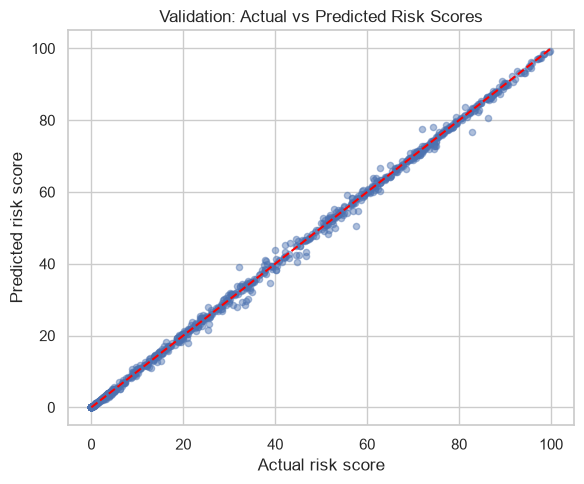

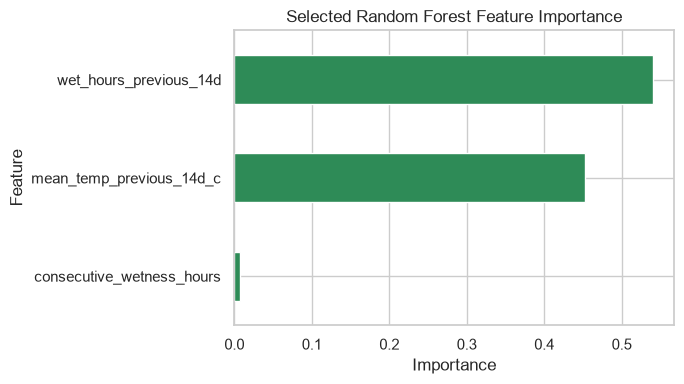

In [7]:
# Compare model settings
rf_100_depth10 = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_100_depth10.fit(X_train, y_train)
pred_100_depth10 = rf_100_depth10.predict(X_validation)

rf_200_depth15 = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_200_depth15.fit(X_train, y_train)
pred_200_depth15 = rf_200_depth15.predict(X_validation)

rf_300_unlimited = RandomForestRegressor(n_estimators=300, max_depth=None, random_state=42, n_jobs=-1)
rf_300_unlimited.fit(X_train, y_train)
pred_300_unlimited = rf_300_unlimited.predict(X_validation)

models = {
    "Baseline: 100 trees, unlimited depth": rf_baseline,
    "100 trees, depth 10": rf_100_depth10,
    "200 trees, depth 15": rf_200_depth15,
    "300 trees, unlimited depth": rf_300_unlimited,
}
predictions = {
    "Baseline: 100 trees, unlimited depth": baseline_predictions,
    "100 trees, depth 10": pred_100_depth10,
    "200 trees, depth 15": pred_200_depth15,
    "300 trees, unlimited depth": pred_300_unlimited,
}

comparison_rows = []
for setting, prediction in predictions.items():
    comparison_rows.append({
        "Setting": setting,
        "MAE": mean_absolute_error(y_validation, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_validation, prediction)),
        "R2": r2_score(y_validation, prediction),
    })
comparison_table = pd.DataFrame(comparison_rows).set_index("Setting")
display(comparison_table.round(4))

best_setting = comparison_table["MAE"].idxmin()
selected_model = models[best_setting]
selected_predictions = predictions[best_setting]
selected_metrics = comparison_table.loc[best_setting]
print("Selected model:", best_setting)

# Plot actual versus predicted scores for the selected model
plt.figure(figsize=(6, 5))
plt.scatter(y_validation, selected_predictions, alpha=0.45, s=20)
plt.plot([0, 100], [0, 100], color="red", linestyle="--")
plt.xlabel("Actual risk score")
plt.ylabel("Predicted risk score")
plt.title("Validation: Actual vs Predicted Risk Scores")
plt.tight_layout()
plt.show()

# Plot feature importance
importance = pd.Series(selected_model.feature_importances_, index=FEATURES).sort_values()
importance.plot(kind="barh", color="seagreen", figsize=(7, 4))
plt.title("Selected Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 8. Risk Level Predictions

Clip a separate copy of predictions to 0?100 for category conversion. Regression metrics above use the raw predictions.

Validation accuracy: 0.9767
Validation macro F1: 0.9767
              precision    recall  f1-score   support

     No Risk       0.98      0.99      0.99       225
         Low       0.96      0.96      0.96       225
    Moderate       0.97      0.96      0.97       225
        High       0.99      0.99      0.99       225

    accuracy                           0.98       900
   macro avg       0.98      0.98      0.98       900
weighted avg       0.98      0.98      0.98       900



,No Risk,Low,Moderate,High
No Risk,223,2,0,0
Low,4,217,4,0
Moderate,0,6,217,2
High,0,0,3,222


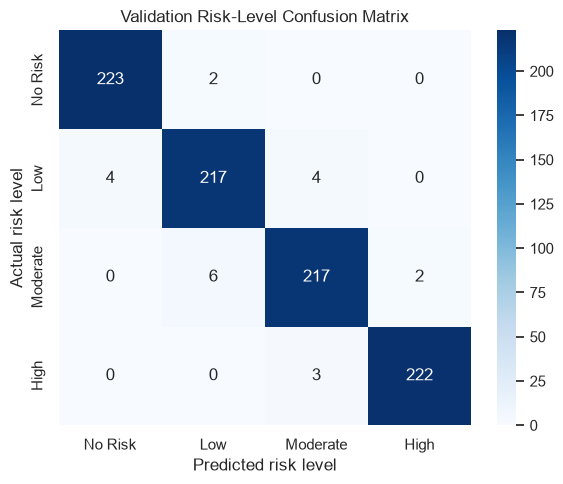

Misclassified validation records: 21
Misclassified records within 2 score points of a threshold: 17


In [8]:
# Convert predictions to risk levels
risk_labels = ["No Risk", "Low", "Moderate", "High"]
thresholds = {"No Risk": "score < 5", "Low": "5 <= score < 30", "Moderate": "30 <= score < 65", "High": "65 <= score <= 100"}
clipped_predictions = np.clip(selected_predictions.copy(), 0, 100)
predicted_levels = pd.cut(
    clipped_predictions,
    bins=[-np.inf, 5, 30, 65, np.inf],
    right=False,
    labels=risk_labels,
)
actual_levels = validation_df["risk_level"]

validation_accuracy = accuracy_score(actual_levels, predicted_levels)
validation_macro_f1 = f1_score(actual_levels, predicted_levels, average="macro")
report_dict = classification_report(actual_levels, predicted_levels, labels=risk_labels, output_dict=True, zero_division=0)
print("Validation accuracy:", round(validation_accuracy, 4))
print("Validation macro F1:", round(validation_macro_f1, 4))
print(classification_report(actual_levels, predicted_levels, labels=risk_labels, zero_division=0))

confusion = confusion_matrix(actual_levels, predicted_levels, labels=risk_labels)
confusion_table = pd.DataFrame(confusion, index=risk_labels, columns=risk_labels)
display(confusion_table)

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_table, annot=True, fmt="d", cmap="Blues")
plt.title("Validation Risk-Level Confusion Matrix")
plt.xlabel("Predicted risk level")
plt.ylabel("Actual risk level")
plt.tight_layout()
plt.show()

wrong_class = np.asarray(actual_levels.astype(str)) != np.asarray(predicted_levels.astype(str))
threshold_distances = np.min(np.abs(y_validation.to_numpy()[:, None] - np.array([5, 30, 65])), axis=1)
print("Misclassified validation records:", int(wrong_class.sum()))
print("Misclassified records within 2 score points of a threshold:", int((wrong_class & (threshold_distances <= 2)).sum()))


## 9. Compare with Scoring Formula

The original project heuristic is deterministic and provides a strong baseline. It is not a published infection-probability equation.

In [9]:
# Compare with the original project score formula
T14 = X_validation["mean_temp_previous_14d_c"].to_numpy(dtype=float)
LW14 = X_validation["wet_hours_previous_14d"].to_numpy(dtype=float)
C = X_validation["consecutive_wetness_hours"].to_numpy(dtype=float)

TempSuit = np.where(T14 <= 25, (T14 - 8) / 17, (37.5 - T14) / 12.5)
TempSuit = np.clip(TempSuit, 0, 1)
WetAnchor = np.where((T14 > 21) & (T14 <= 25), 130, 160)
WetSuit = np.clip((LW14 - 30) / (WetAnchor + 45 - 30), 0, 1)
Continuity = np.clip(C / 18, 0, 1)
formula_predictions = np.round(np.clip(100 * TempSuit * (0.88 * WetSuit + 0.12 * Continuity), 0, 100), 3)

formula_mae = mean_absolute_error(y_validation, formula_predictions)
formula_rmse = np.sqrt(mean_squared_error(y_validation, formula_predictions))
formula_comparison = pd.DataFrame([
    {"Method": "Selected Random Forest", "MAE": float(selected_metrics["MAE"]), "RMSE": float(selected_metrics["RMSE"])},
    {"Method": "Original score formula", "MAE": float(formula_mae), "RMSE": float(formula_rmse)},
])
display(formula_comparison.round(5))


,Method,MAE,RMSE
0,Selected Random Forest,0.56401,1.01173
1,Original score formula,0.00102,0.00150


## 10. Save Model

Save only the selected Random Forest model and a small JSON file with its settings and validation results.

In [10]:
# Save the selected model
MODEL_DIR = PROJECT_ROOT / "Models" / "yellow_sigatoka" / "random_forest"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "random_forest_model.joblib"
metadata_path = MODEL_DIR / "random_forest_metadata.json"

joblib.dump(selected_model, model_path)

selected_parameters = {
    "n_estimators": int(selected_model.n_estimators),
    "max_depth": selected_model.max_depth,
    "random_state": int(selected_model.random_state),
    "n_jobs": selected_model.n_jobs,
}
metadata = {
    "features": FEATURES,
    "target": TARGET,
    "selected_model": best_setting,
    "parameters": selected_parameters,
    "validation_regression_metrics": {
        "mae": float(selected_metrics["MAE"]),
        "rmse": float(selected_metrics["RMSE"]),
        "r2": float(selected_metrics["R2"]),
    },
    "validation_risk_level_metrics": {
        "accuracy": float(validation_accuracy),
        "macro_f1": float(validation_macro_f1),
    },
    "risk_thresholds": thresholds,
    "limitation": "Targets are project-defined synthetic environmental suitability scores, not measured disease outcomes.",
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model:", model_path)
print("Saved metadata:", metadata_path)


Saved model: C:\Users\HP\Desktop\ML training\Models\yellow_sigatoka\random_forest\random_forest_model.joblib
Saved metadata: C:\Users\HP\Desktop\ML training\Models\yellow_sigatoka\random_forest\random_forest_metadata.json


## 11. Training Summary

Validation results measure how well the model reproduces the synthetic score rule. They do not measure real plantation infection prediction.

In [11]:
# Save the training report
report_path = PROJECT_ROOT / "reports" / "yellow_sigatoka" / "random_forest" / "Random_Forest_Training_Report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)

comparison_lines = ["| Setting | MAE | RMSE | R2 |", "|---|---:|---:|---:|"]
for setting, row in comparison_table.iterrows():
    comparison_lines.append(f"| {setting} | {row['MAE']:.4f} | {row['RMSE']:.4f} | {row['R2']:.4f} |")

class_lines = ["| Risk level | Precision | Recall | F1-score | Support |", "|---|---:|---:|---:|---:|"]
for level in risk_labels:
    row = report_dict[level]
    class_lines.append(f"| {level} | {row['precision']:.4f} | {row['recall']:.4f} | {row['f1-score']:.4f} | {int(row['support'])} |")
confusion_lines = ["| Actual \ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
for level, row in zip(risk_labels, confusion):
    confusion_lines.append("| " + level + " | " + " | ".join(str(int(v)) for v in row) + " |")

report_lines = [
    "# Yellow Sigatoka Random Forest Training Report", "",
    "## Dataset and features",
    f"- Training: {len(train_df):,} rows; validation: {len(validation_df):,} rows. The splits were kept separate.",
    "- Features: `mean_temp_previous_14d_c`, `wet_hours_previous_14d`, `consecutive_wetness_hours`.",
    "- Target: `risk_score`. No other fields were used as predictors.", "",
    "## Model settings and validation comparison",
    "The baseline and three requested alternatives were trained with random_state 42 and n_jobs -1. Validation MAE was used to select the model.",
    *comparison_lines, "",
    f"Selected model: **{best_setting}**.",
    f"Selected validation MAE {selected_metrics['MAE']:.4f}, RMSE {selected_metrics['RMSE']:.4f}, and R2 {selected_metrics['R2']:.4f}.",
    f"Selected model raw prediction range: {selected_predictions.min():.4f} to {selected_predictions.max():.4f}.", "",
    "## Risk-level validation",
    f"Accuracy: {validation_accuracy:.4f}; macro F1: {validation_macro_f1:.4f}.",
    *class_lines, "",
    *confusion_lines, "",
    f"Misclassified rows: {int(wrong_class.sum())}; misclassified rows within 2 score points of a risk threshold: {int((wrong_class & (threshold_distances <= 2)).sum())}.", "",
    "## Formula baseline",
    f"Original formula validation MAE: {formula_mae:.5f}; RMSE: {formula_rmse:.5f}.",
    "The formula is expected to be nearly exact because it generated the targets. Random Forest is an imitation model and should not be described as superior if its errors are larger.", "",
    "## Saved files",
    f"- Model: `{model_path.relative_to(PROJECT_ROOT).as_posix()}`.",
    f"- Metadata: `{metadata_path.relative_to(PROJECT_ROOT).as_posix()}`.", "",
    "## Limitations and next step",
    "The target is a synthetic environmental suitability score, not observed disease occurrence or infection probability. Strong results show rule imitation, not validated plantation disease prediction. Synthetic source-weather windows may overlap across scenarios. Compare this model with XGBoost using the same train/validation split, then conduct the planned final comparison before accessing the reserved test set.",
]
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report:", report_path)
print("Selected parameters:", selected_parameters)


Saved report: C:\Users\HP\Desktop\ML training\reports\yellow_sigatoka\random_forest\Random_Forest_Training_Report.md
Selected parameters: {'n_estimators': 300, 'max_depth': None, 'random_state': 42, 'n_jobs': -1}


<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:13: SyntaxWarning: invalid escape sequence '\ '
C:\Users\HP\AppData\Local\Temp\ipykernel_7560\4236629362.py:13: SyntaxWarning: invalid escape sequence '\ '
  confusion_lines = ["| Actual \ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
